# Iris Flower Classification

## Objective
The objective of this project is to build a machine learning model that predicts the species of an Iris flower based on its sepal and petal measurements.

## Problem Type
Supervised Machine Learning — Classification

## Dataset
The Iris dataset contains 150 samples belonging to 3 species:
- Iris Setosa
- Iris Versicolor
- Iris Virginica

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

In [4]:
iris = load_iris()
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
df["species"] = iris.target
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nSpecies mapping:")
print(iris.target_names)

Dataset shape: (150, 5)

Column names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')

Species mapping:
['setosa' 'versicolor' 'virginica']


In [6]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [7]:
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0


In [8]:
df["species_name"] = df["species"].map(
    {0: "setosa", 1: "versicolor", 2: "virginica"}
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [9]:
df["species_name"].value_counts()

,count
species_name,
setosa,50
versicolor,50
virginica,50


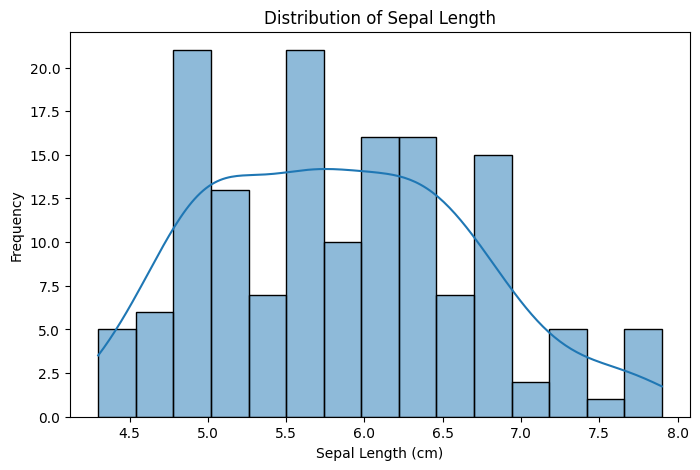

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="sepal length (cm)",
    bins=15,
    kde=True
)

plt.title("Distribution of Sepal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Frequency")

plt.show()

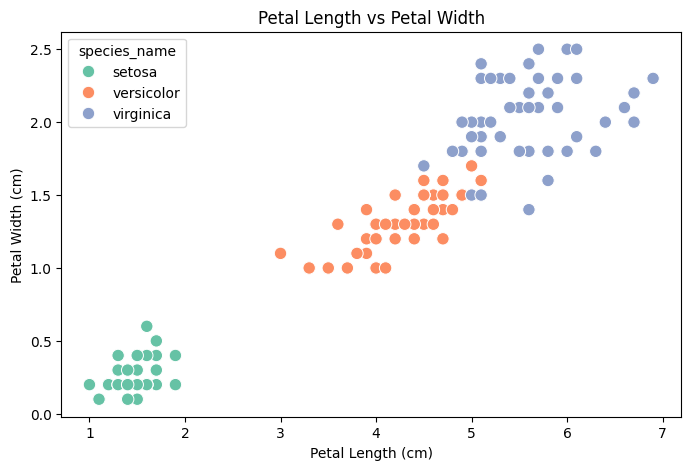

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species_name",
    palette="Set2",
    s=80
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.show()

In [12]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df.drop(columns=["species", "species_name"])
y = df["species"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [13]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training labels: (120,)
Testing labels: (30,)


#KNN ALGORITHM

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Create the ML pipeline
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=7))
])

# Train the model
knn_model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [15]:
y_pred = knn_model.predict(X_test)

print("Predictions:", y_pred)
print("Actual labels:", y_test.to_numpy())

Predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 2 2 1 1 0 2 0]
Actual labels: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


Calculating Accuracy

In [16]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.9666666666666667
Accuracy percentage: 96.66666666666667 %


In [17]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



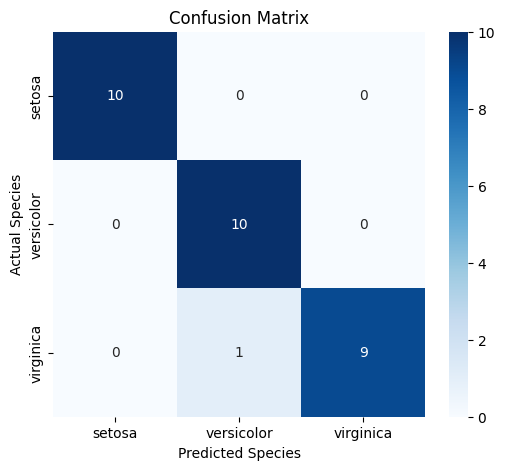

In [18]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix")

plt.show()

Checking which value of k is best

In [19]:
from sklearn.model_selection import cross_val_score

k_values = range(1, 21)
cv_scores = []

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_scores.append(scores.mean())

print("Experiment completed!")

Experiment completed!


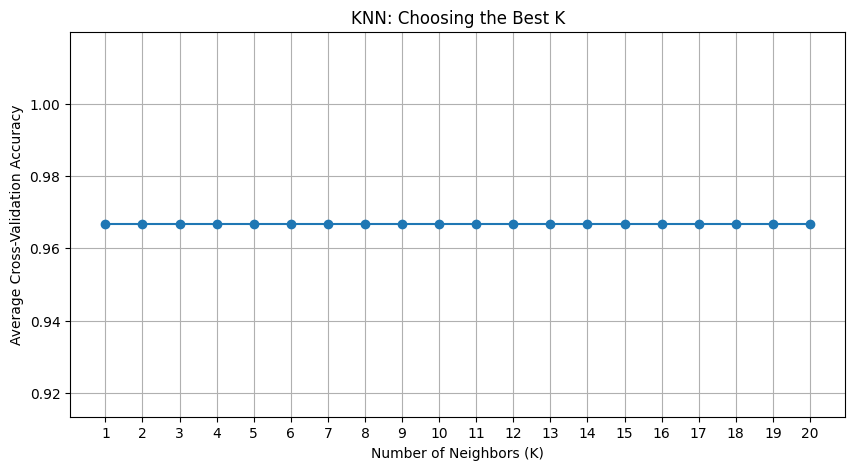

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(k_values, cv_scores, marker="o")

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Average Cross-Validation Accuracy")
plt.title("KNN: Choosing the Best K")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000))
    ])
}

In [22]:
results = {}

for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)

    # Predict on test data
    predictions = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, predictions)

    results[name] = accuracy

    print(f"{name}: {accuracy:.4f}")

KNN: 0.9333
Decision Tree: 0.9333
Logistic Regression: 0.9333


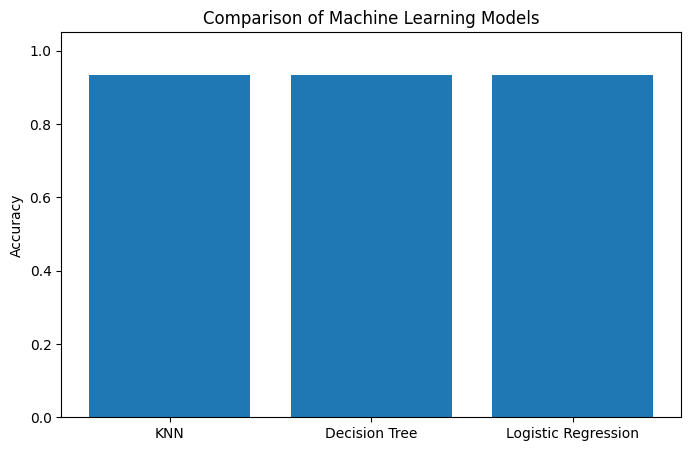

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(results.keys(), results.values())

plt.ylabel("Accuracy")
plt.title("Comparison of Machine Learning Models")
plt.ylim(0, 1.05)

plt.show()

In [27]:
new_flower = pd.DataFrame(
    [[6.3, 3.3, 6.0, 2.5]],
    columns=iris.feature_names
)

model = models["Logistic Regression"]


prediction = model.predict(new_flower)


predicted_species = iris.target_names[prediction[0]]

print("Predicted species:", predicted_species)

Predicted species: virginica


In [28]:
import joblib

# Save our trained KNN model
joblib.dump(knn_model, "iris_knn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [30]:

loaded_model = joblib.load("iris_knn_model.pkl")

new_flower = pd.DataFrame(
    [[6.3, 3.3, 6.0, 2.5]],
    columns=iris.feature_names
)
test_prediction = loaded_model.predict(new_flower)

print("Prediction after loading:", iris.target_names[test_prediction[0]])

Prediction after loading: virginica


In [31]:
from google.colab import files

files.download("iris_knn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>